# Fine-tuning Spotiflow on simulated CBED patterns

`load_diffraction.ipynb` is the **zero-shot reference**: it runs pretrained Spotiflow models on BW and scores them against spot centres taken from `dataPots`. This notebook prepares and runs fine-tuning on the full dataset (25 materials × 3 probe angles × 25 thicknesses, 20–500 Å): the 24 folders in `selected_folders` plus SiO₂, which is stored in the parent folder `dummy_data/`.

**Sections**

1. **Label audit** (this section). Before training on the reference labels, check that they are what we think they are:
   - 1.1 reproduce the reference labels on one known case (BW, 4 mrad, 40 Å: 280 candidate centres, 150 visible);
   - 1.2 audit 12 patterns (BW and Co₃(O₂F)₂ × 1, 2, 4 mrad × 20, 500 Å);
   - 1.3 centre alignment on the separated disks at 1 mrad;
   - 1.4 candidates that pass the visibility test because of a neighbour, at 4 mrad (separated with a disk fit; *experimental*, see 1.5);
   - 1.5 decision: is *visible* a reliable training target?
2. **Zero-shot baseline** on all 25 materials: the shared pipelines of `load_diffraction.ipynb`, before any fine-tuning.
3. Fine-tuning *(to do)*.

The label code below is **copied unchanged** from `load_diffraction.ipynb` (section 2, with the 3 × 3 visibility box), so matching its counts checks the loader and the labels, not a re-implementation.

In [1]:
import glob
import os
import re
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle
from scipy.ndimage import maximum_filter
from scipy.spatial import cKDTree
from skimage.feature import peak_local_max

root = os.environ.get("AUDIT_ROOT", "/mnt/data/DINOV3/dinov3/dummy_data/selected_folders")
CHECK_REFERENCE = "AUDIT_ROOT" not in os.environ  # the 280 / 150 check only applies to the real data

# label settings, identical to load_diffraction.ipynb
GT_REL = 0.02      # ground truth = dataPots local maxima above 2 % of the maximum, >= 3 px apart
BEAM_R = 3         # px: candidates this close to the central beam are excluded
FLOOR_REL = 1e-4   # visibility floor = max(dataMeas) * 1e-4
VIS_BOX = 3        # visibility box (3 x 3)

# Okabe-Ito colours (colour-blind safe), as in the reference notebook
BLUE, SKY, ORANGE, YELLOW = "#0072B2", "#56B4E9", "#E69F00", "#F0E442"  # no red / green

GRAY = plt.get_cmap("gray").copy()
GRAY.set_bad("black")  # zero pixels are black, not blank, on a log scale

SUB = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")


def norm(name):
    """Compare formulas without subscripts or spaces: 'Co₃(O₂F)₂' == 'Co3(O2F)2'."""
    return re.sub(r"\s", "", str(name).translate(SUB))


MATERIALS = {}  # normalised formula -> (folder, metadata)
# the 24 material folders, plus SiO2, whose files sit directly in the parent folder
for f in sorted(glob.glob(f"{root}/*")) + [str(Path(root).parent)]:
    if os.path.exists(f"{f}/simulation_dataframe.pkl"):
        meta = pd.read_pickle(f"{f}/simulation_dataframe.pkl")
        MATERIALS[norm(meta["pretty_formula"].iloc[0])] = (f, meta)
print(f"{len(MATERIALS)} materials in {root}:\n{', '.join(MATERIALS)}")

25 materials in /mnt/data/DINOV3/dinov3/dummy_data/selected_folders:
Co3(O2F)2, BW, SiI3, Mg2B4H22C2S, AlPO4, Mn6O5F7, Pr4Sb3, Al(NiO2)3, AlPt2, ErCo5Si3, AlCo3, U3Bi4Rh3, ZrSn3, Ba2Mn3O8, Na2O, HoTe3, CoSbS, SbPbO3, Nd4Rh6Pb19, Li7Mn2(CoO4)3, NbTe4Ir, LiMnCrO4, RbCaMg6, FeB, SiO2


In [2]:
def load_slice(material, angle, thickness):
    """dataMeas, dataPots, dataProbe for one material, probe semi-angle (mrad) and thickness (Å).
    Same file and slice selection as load_diffraction.ipynb (first simulation with that angle)."""
    folder, meta = MATERIALS[norm(material)]
    uid = meta.index[meta["probeSemiangle"] == angle][0]
    with h5py.File(f"{folder}/{uid}_training.h5", "r") as h:
        stored = h["thicknesses"][:]
        hits = np.where(stored == thickness)[0]
        if not len(hits):
            raise ValueError(f"{material}: {thickness} Å not stored (stored: {stored.min()}–{stored.max()} Å)")
        t = int(hits[0])
        return h["dataMeas"][..., t], h["dataPots"][..., t], h["dataProbe"][:]


def disk_radius(probe):
    """Disk radius in px, from the area of the probe aperture (reference notebook)."""
    return np.sqrt((probe > probe.max() / 2).sum() / np.pi)


def off_beam(pts, centre, r=BEAM_R):
    return np.hypot(*(np.asarray(pts)[:, :2] - centre).T) > r


def ground_truth(img, gt):
    """Copied from load_diffraction.ipynb, section 2: beam centre, candidate centres, visibility (3 x 3), floor."""
    beam = np.argwhere(img > img.max() / 2).mean(axis=0)
    points = peak_local_max(gt, min_distance=3, threshold_rel=GT_REL, exclude_border=False)  # (row, col) = (y, x)
    points = points[off_beam(points, beam)]
    floor = img.max() * FLOOR_REL
    visible = maximum_filter(img, size=VIS_BOX)[points[:, 0], points[:, 1]] >= floor
    return dict(beam=beam, points=points, visible=visible, floor=floor)

## 1.1 Reproduce the reference labels: BW, 4 mrad, 40 Å

The reference notebook gives **280 candidate centres and 150 visible** for this pattern. If the counts match, the loader (file, angle, thickness slice) and the label code reproduce the reference. The figure shows the candidates on the log-scaled pattern, which ones pass the 3 × 3 visibility test, and the central-beam exclusion:

- **solid yellow circle** (around the yellow ☆ beam centre): candidates within 3 px of the beam centre are excluded from the labels;
- **dashed white circle** (radius r + 3): the area the ring-correlation pipeline masks out; candidates inside it can never be detected by that pipeline.

BW | 4 mrad | 40 Å   disk radius r = 9.9 px
candidates: 280 (reference 280)   visible: 150 (reference 150)
visible candidates inside the ring-correlation beam mask (r + 3 = 12.9 px): 2
PASS: loader and labels reproduce load_diffraction.ipynb


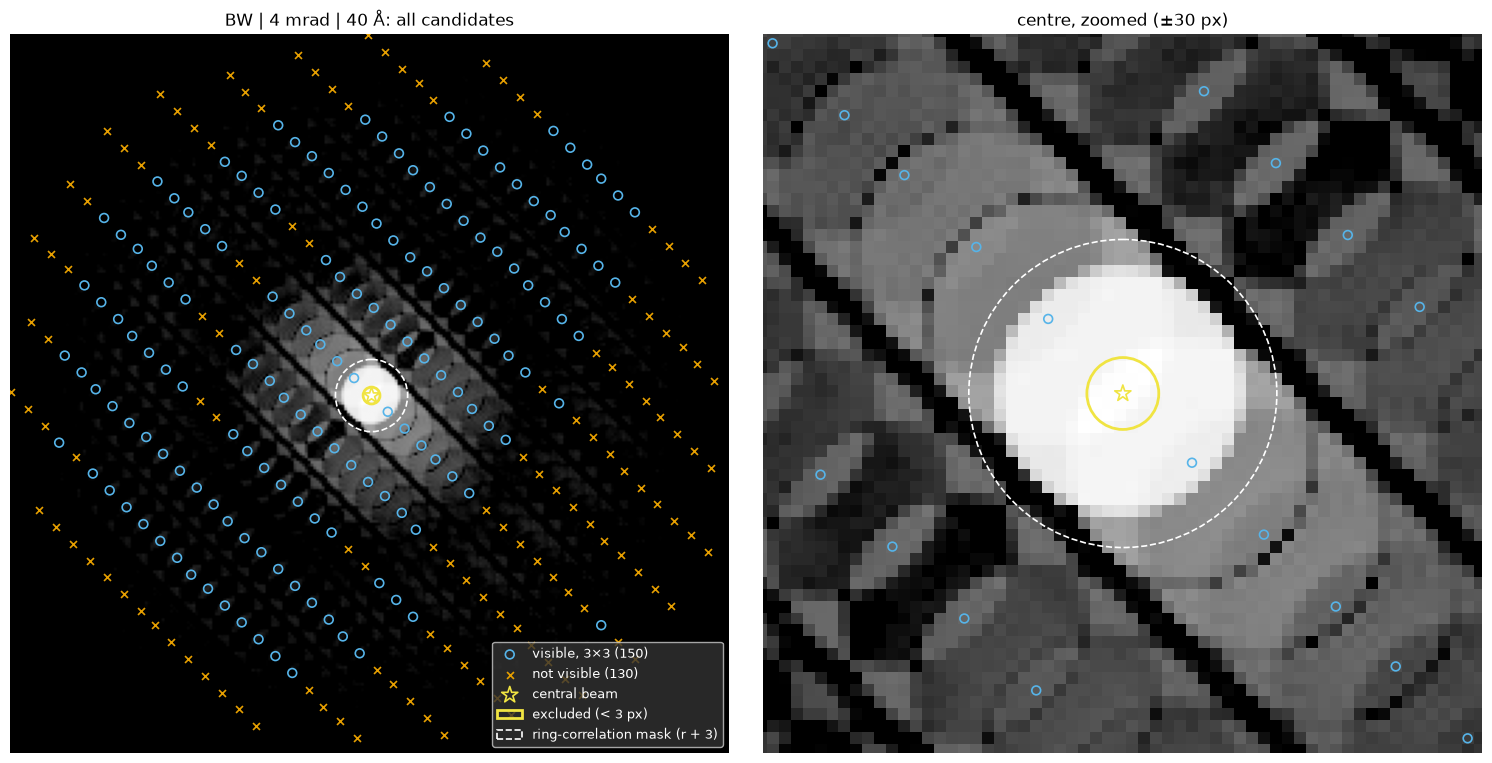

In [3]:
REF = dict(material="BW", angle=4, thickness=40, n_candidates=280, n_visible=150)

img, gt, probe = load_slice(REF["material"], REF["angle"], REF["thickness"])
g = ground_truth(img, gt)
r = disk_radius(probe)
n_cand, n_vis = len(g["points"]), int(g["visible"].sum())
in_mask = ~off_beam(g["points"], g["beam"], r + 3)

print(f"{REF['material']} | {REF['angle']} mrad | {REF['thickness']} Å   disk radius r = {r:.1f} px")
print(f"candidates: {n_cand} (reference {REF['n_candidates']})   visible: {n_vis} (reference {REF['n_visible']})")
print(f"visible candidates inside the ring-correlation beam mask (r + 3 = {r + 3:.1f} px): {(in_mask & g['visible']).sum()}")
if CHECK_REFERENCE:
    # the reference notebook picks its material as sorted(glob)[1]; make sure that is the same folder
    assert sorted(glob.glob(f"{root}/*"))[1] == MATERIALS["BW"][0], "BW is not the reference notebook's MATERIAL_INDEX = 1"
    assert (n_cand, n_vis) == (REF["n_candidates"], REF["n_visible"]), "labels do NOT reproduce the reference"
    print("PASS: loader and labels reproduce load_diffraction.ipynb")
else:
    print("(AUDIT_ROOT is set: reference counts not checked)")


def show_labels(ax, img, g, r, title, zoom=None):
    """Log-scaled pattern with candidates: visible (o), not visible (x), beam (*), exclusion circles."""
    ax.imshow(img, cmap=GRAY, norm=LogNorm(vmin=g["floor"], vmax=img.max()))
    p, v = g["points"], g["visible"]
    ax.scatter(p[v, 1], p[v, 0], s=40, marker="o", facecolors="none", edgecolors=SKY, linewidths=1.2,
               label=f"visible, 3×3 ({v.sum()})")
    ax.scatter(p[~v, 1], p[~v, 0], s=25, marker="x", c=ORANGE, linewidths=1.2, label=f"not visible ({(~v).sum()})")
    by, bx = g["beam"]
    ax.scatter(bx, by, s=150, marker="*", facecolors="none", edgecolors=YELLOW, linewidths=1.2, label="central beam")
    ax.add_patch(Circle((bx, by), BEAM_R, fill=False, ec=YELLOW, lw=2, label=f"excluded (< {BEAM_R} px)"))
    ax.add_patch(Circle((bx, by), r + 3, fill=False, ec="white", lw=1.2, ls="--", label=f"ring-correlation mask (r + 3)"))
    if zoom:
        ax.set_xlim(bx - zoom, bx + zoom)
        ax.set_ylim(by + zoom, by - zoom)
    ax.set_title(title)
    ax.axis("off")


fig, axs = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True)
show_labels(axs[0], img, g, r, f"{REF['material']} | {REF['angle']} mrad | {REF['thickness']} Å: all candidates")
show_labels(axs[1], img, g, r, "centre, zoomed (±30 px)", zoom=30)
axs[0].legend(loc="lower right", fontsize=9, facecolor="0.2", labelcolor="white")
plt.show()

## 1.2 Audit 12 patterns

BW and Co₃(O₂F)₂, at 1, 2 and 4 mrad, at 20 and 500 Å. For each candidate centre `candidate_table` records:

| column | meaning |
|---|---|
| `pots` | its `dataPots` peak, relative to the pattern's strongest peak |
| `own` | `dataMeas` at the centre pixel itself, in units of the floor |
| `box3`, `box5` | maximum of `dataMeas` in the 3 × 3 / 5 × 5 box, in units of the floor |
| `visible` | the reference label: `box3 ≥ 1` |
| `box_only` | visible only because the 3 × 3 box reached a brighter pixel: `box3 ≥ 1` but `own < 1` |
| `n_cover` | number of other candidates whose disk (radius r) covers this centre |
| `own_fit` | the disk's **own** intensity, in units of the floor, from the disk fit below |
| `neighbour_lit` | visible, but its own disk is below the floor (`own_fit < 1`): the light at its centre comes from neighbouring disks |

**Disk fit.** Every Bragg disk is a shifted copy of the probe, so the pattern is modelled as `dataMeas ≈ Σₖ aₖ · probe(centre k)` with `aₖ ≥ 0`. The centres are the central beam, the labelled candidates and the weaker `dataPots` peaks (0.5–2 %, fitted but not labelled, so their light is not credited to a labelled neighbour). The fit is weighted for relative error, so faint disks count as much as bright ones. `aₖ` separates a disk's own intensity from its neighbours' where disks overlap, which the 3 × 3 test on `dataMeas` cannot.

The model adds disk *intensities*; real CBED disks interfere where they overlap and are not perfectly uniform. `fit_error` (mean |model − data| / data over pixels above the floor) says how well the model holds. If it is large, treat `own_fit` as approximate.

In [4]:
from scipy import sparse
from scipy.optimize import lsq_linear

AUDIT = [(m, a, t) for m in ["BW", "Co3(O2F)2"] for a in [1, 2, 4] for t in [20, 500]]
EXTRA_REL = 0.005  # weaker dataPots peaks (0.5-2 %) are fitted as disks too, but not labelled


def fit_disks(img, probe, centres):
    """Non-negative fit  img ~ sum_k a_k * probe shifted to centre k,  weighted for relative error.
    Returns a_k (image units), the model image and fit_error (mean relative error where img >= floor)."""
    pr = probe / probe.max()
    py, px = np.rint(np.argwhere(pr > 0.5).mean(axis=0)).astype(int)      # probe centre in its array
    sy, sx = np.nonzero(pr > 1e-3)                                         # probe support
    vals, dy, dx = pr[sy, sx], sy - py, sx - px
    H, W = img.shape
    rows, cols, data = [], [], []
    for k, (cy, cx) in enumerate(np.rint(centres).astype(int)):
        yy, xx = dy + cy, dx + cx
        ok = (yy >= 0) & (yy < H) & (xx >= 0) & (xx < W)
        rows.append(yy[ok] * W + xx[ok]); cols.append(np.full(ok.sum(), k)); data.append(vals[ok])
    A = sparse.csr_matrix((np.concatenate(data), (np.concatenate(rows), np.concatenate(cols))), shape=(H * W, len(centres)))
    b = img.ravel().astype(float)
    floor = img.max() * FLOOR_REL
    w = 1 / (np.abs(b) + floor)
    a = lsq_linear(sparse.diags(w) @ A, w * b, bounds=(0, np.inf), lsmr_tol="auto").x
    model = A @ a
    bright = b >= floor
    return a, model.reshape(H, W), float(np.mean(np.abs(model[bright] - b[bright]) / b[bright]))


def candidate_table(img, gt, probe):
    g = ground_truth(img, gt)
    p, floor, r = g["points"], g["floor"], disk_radius(probe)
    y, x = p[:, 0], p[:, 1]
    df = pd.DataFrame(dict(
        y=y, x=x,
        pots=gt[y, x] / gt.max(),
        own=img[y, x] / floor,
        box3=maximum_filter(img, size=3)[y, x] / floor,
        box5=maximum_filter(img, size=5)[y, x] / floor,
        visible=g["visible"],
    ))
    df["box_only"] = df.visible & (df.own < 1)
    tree = cKDTree(p)
    df["nn_dist"] = tree.query(p, k=2)[0][:, 1]
    df["n_cover"] = [len(js) - 1 for js in tree.query_ball_point(p, r)]     # other disks covering this centre
    # disk fit: beam + labelled candidates + weaker (unlabelled) dataPots peaks
    extra = peak_local_max(gt, min_distance=3, threshold_rel=EXTRA_REL, exclude_border=False)
    labelled = {tuple(q) for q in p}
    extra = np.array([q for q in extra if tuple(q) not in labelled and off_beam(q[None], g["beam"])[0]]).reshape(-1, 2)
    centres = np.vstack([g["beam"][None], p, extra])
    a, model, err = fit_disks(img, probe, centres)
    df["own_fit"] = a[1:1 + len(p)] / floor
    df["neighbour_lit"] = df.visible & (df.own_fit < 1)
    df["in_ring_mask"] = ~off_beam(p, g["beam"], r + 3)
    g.update(model=model, fit_error=err, n_extra=len(extra))
    return df, g, r


rows, TABLES = [], {}
for material, angle, thickness in AUDIT:
    img, gt, probe = load_slice(material, angle, thickness)
    df, g, r = candidate_table(img, gt, probe)
    TABLES[(material, angle, thickness)] = (img, gt, probe, df, g, r)
    s = np.median(df.nn_dist)
    vis = df.visible
    rows.append(dict(material=material, angle=f"{angle} mrad", thickness=f"{thickness} Å", r=round(r, 1),
                     spacing=round(s, 1), eta=round(2 * r / s, 2), candidates=len(df), visible=int(vis.sum()),
                     visible_1x1=int((df.own >= 1).sum()), visible_5x5=int((df.box5 >= 1).sum()),
                     box_only=int(df.box_only.sum()), covered=int((vis & (df.n_cover > 0)).sum()),
                     neighbour_lit=int(df.neighbour_lit.sum()), visible_fit=int((df.own_fit >= 1).sum()),
                     doubtful_frac=round((df.box_only | df.neighbour_lit)[vis].mean(), 3) if vis.any() else np.nan,
                     fit_error=round(g["fit_error"], 3), in_ring_mask=int((df.in_ring_mask & vis).sum())))

audit = pd.DataFrame(rows).set_index(["material", "angle", "thickness"])
print("covered = visible and inside at least one neighbour's disk; visible_fit = own disk above the floor;\n"
      "doubtful = visible but box_only or neighbour_lit\n")
print(audit.to_string())

covered = visible and inside at least one neighbour's disk; visible_fit = own disk above the floor;
doubtful = visible but box_only or neighbour_lit

                              r  spacing   eta  candidates  visible  visible_1x1  visible_5x5  box_only  covered  neighbour_lit  visible_fit  doubtful_frac  fit_error  in_ring_mask
material  angle  thickness                                                                                                                                                          
BW        1 mrad 20 Å       2.6      8.5  0.61         280      170          153          177        17        0             33          137          0.194      0.365             0
                 500 Å      2.6      8.5  0.61         322      294          214          306        80        0            109          185          0.405      0.836             0
          2 mrad 20 Å       4.7      8.5  1.10         280      163          130          176        33        0            11

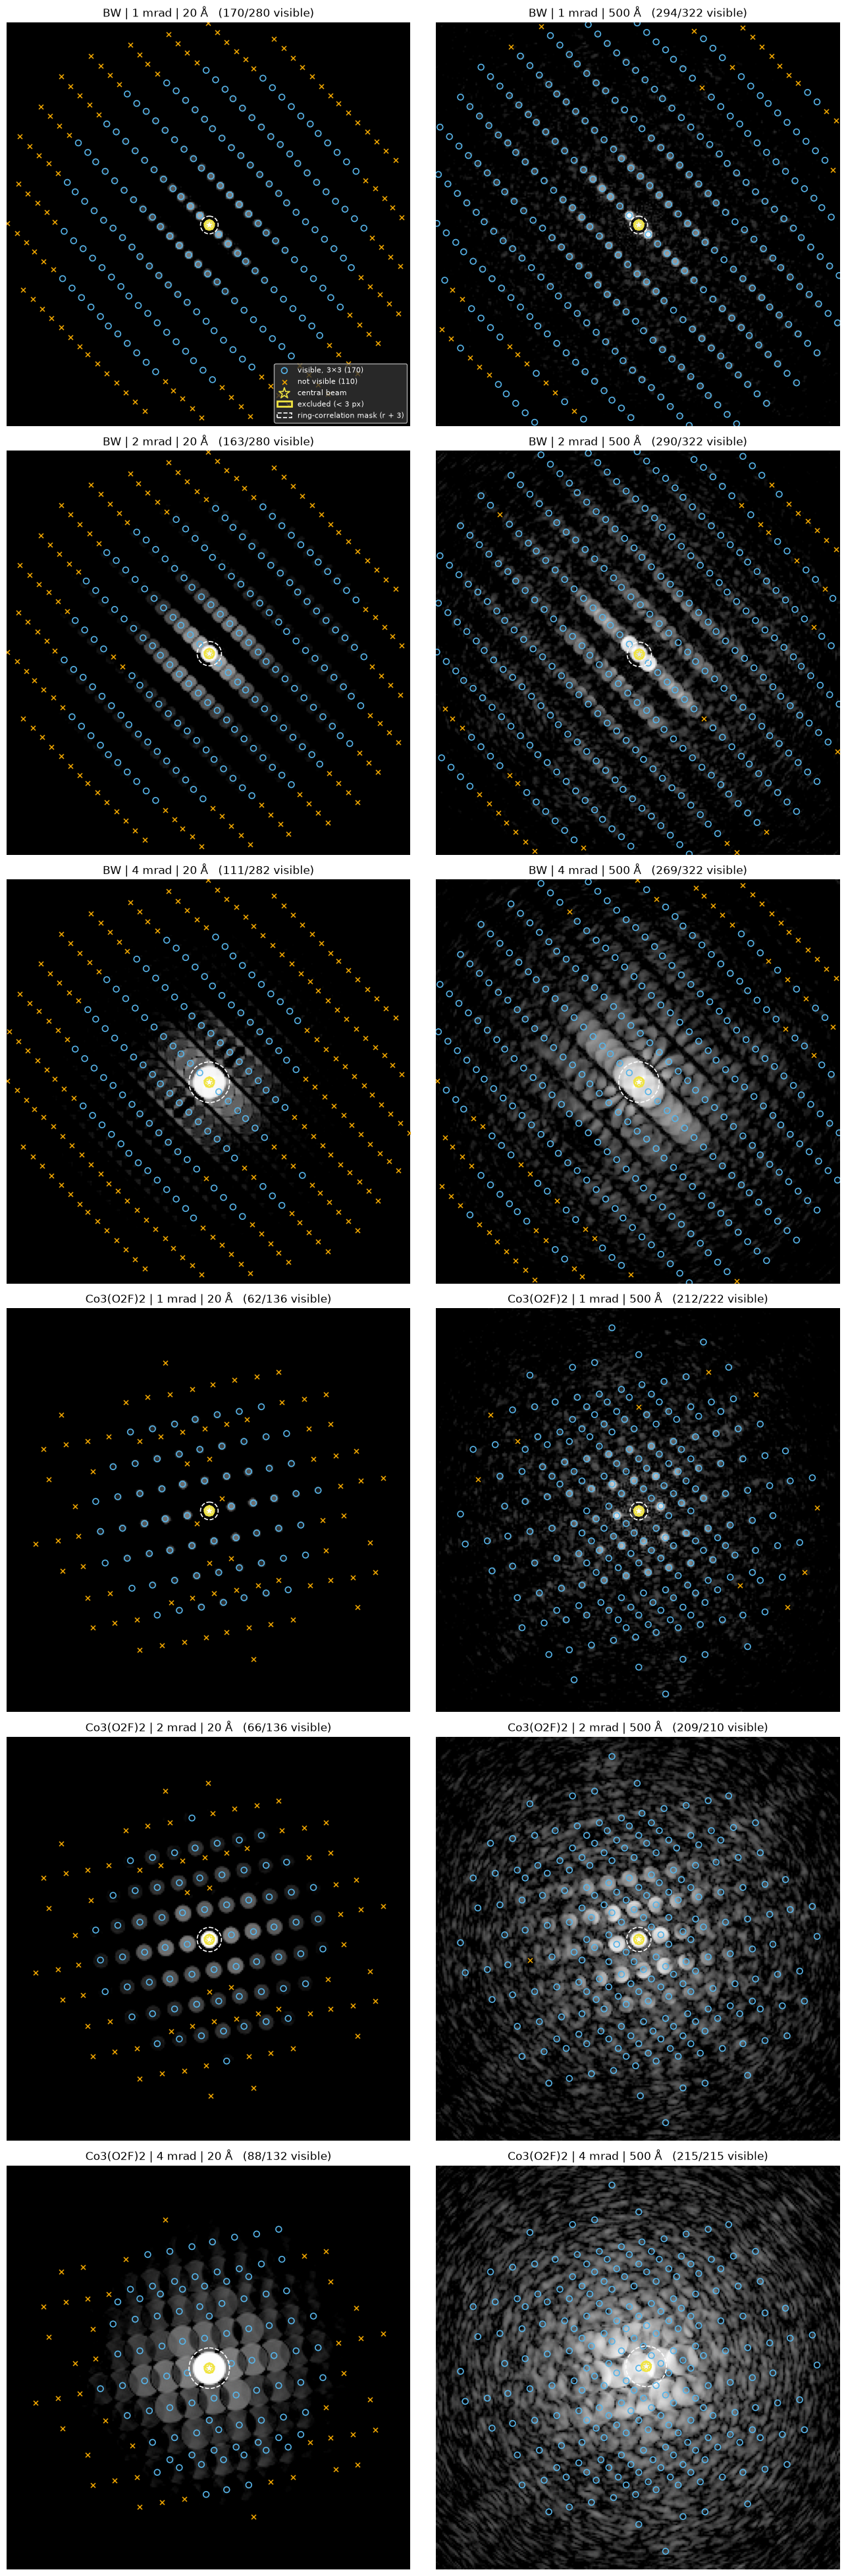

In [5]:
fig, axs = plt.subplots(len(AUDIT) // 2, 2, figsize=(13, 6.5 * len(AUDIT) // 2), constrained_layout=True)
for ax, key in zip(axs.flat, AUDIT):
    img, gt, probe, df, g, r = TABLES[key]
    show_labels(ax, img, g, r, f"{key[0]} | {key[1]} mrad | {key[2]} Å   ({g['visible'].sum()}/{len(g['points'])} visible)")
axs.flat[0].legend(loc="lower right", fontsize=8, facecolor="0.2", labelcolor="white")
plt.show()

## 1.3 Centre alignment at 1 mrad

At 1 mrad the disks are separate, so each visible disk's own centre can be measured from `dataMeas` and compared with its `dataPots` centre. Only isolated, clearly visible disks are used: no other candidate within 2r + 2 px, and centre ≥ 10× the floor. The disk centre is the intensity-weighted centroid of `dataMeas` within r + 1 px of the candidate.

A systematic offset (median `dy`, `dx` away from 0) means the labels are shifted relative to the disks, e.g. a half-pixel convention between `dataPots` and `dataMeas`. Every model trained on these labels would learn that shift. The scatter of offsets (RMS) sets a floor for the localisation accuracy we can claim. The probe's own offset from the array centre is printed too, because the ring-correlation pipeline assumes a centred probe.

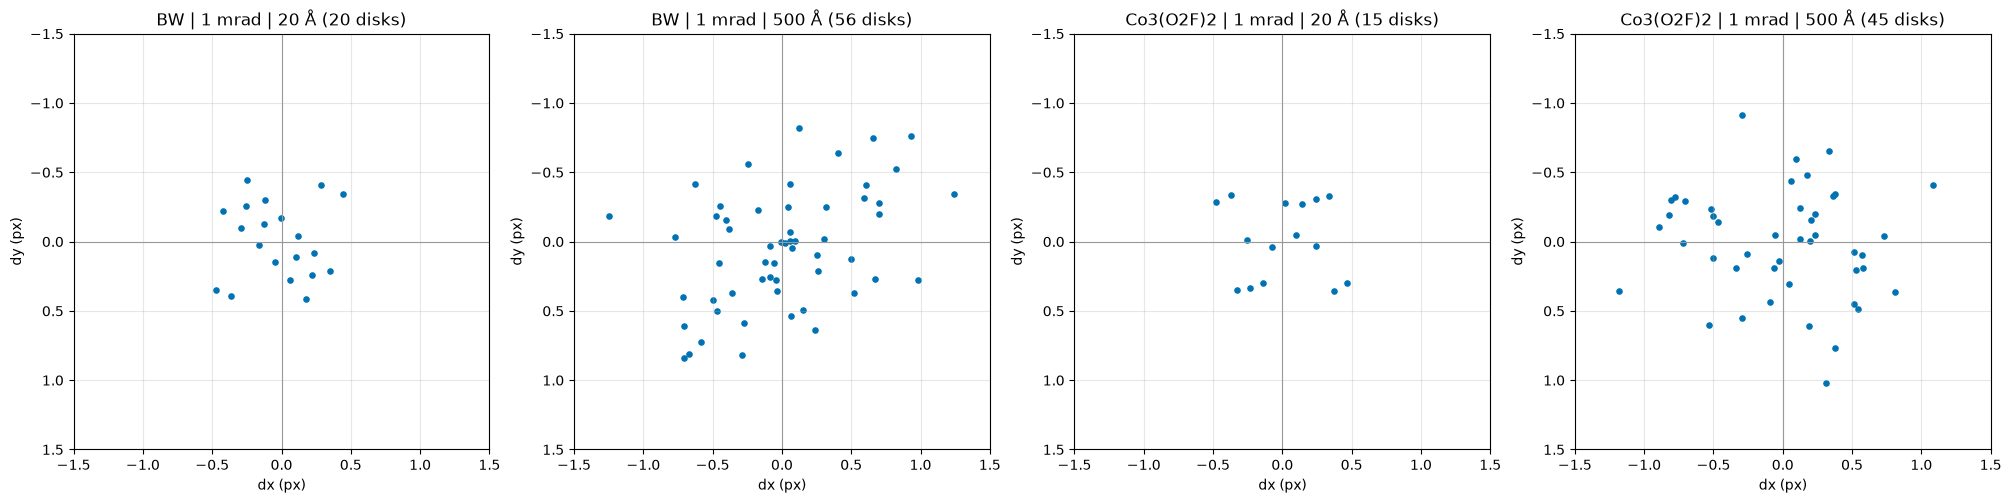

disk centre (dataMeas centroid) minus label centre (dataPots), 1 mrad; probe offset from the array centre

                     disks  median_dy  median_dx    rms  probe_dy  probe_dx
material  thickness                                                        
BW        20 Å          20     -0.010     -0.024  0.373       0.0       0.0
          500 Å         56      0.021      0.010  0.657       0.0       0.0
Co3(O2F)2 20 Å          15     -0.008      0.017  0.394       0.0       0.0
          500 Å         45     -0.017      0.095  0.645       0.0       0.0


In [6]:
def disk_offsets(img, df, r, min_snr=10):
    """(dy, dx) = intensity-weighted centroid of dataMeas within r + 1 px  minus  dataPots centre."""
    yy, xx = np.indices(img.shape)
    sel = df[df.visible & (df.own >= min_snr) & (df.nn_dist > 2 * r + 2)]
    out = []
    for y, x in sel[["y", "x"]].values:
        m = np.hypot(yy - y, xx - x) <= r + 1
        w = img[m]
        out.append(((yy[m] * w).sum() / w.sum() - y, (xx[m] * w).sum() / w.sum() - x))
    return sel.assign(dy=[o[0] for o in out], dx=[o[1] for o in out]) if out else sel.assign(dy=[], dx=[])


align_rows = []
fig, axs = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
for ax, key in zip(axs, [k for k in AUDIT if k[1] == 1]):
    img, gt, probe, df, g, r = TABLES[key]
    off = disk_offsets(img, df, r)
    cy, cx = np.argwhere(probe > probe.max() / 2).mean(axis=0)
    align_rows.append(dict(material=key[0], thickness=f"{key[2]} Å", disks=len(off),
                           median_dy=round(off.dy.median(), 3), median_dx=round(off.dx.median(), 3),
                           rms=round(float(np.sqrt((off.dy ** 2 + off.dx ** 2).mean())), 3) if len(off) else np.nan,
                           probe_dy=round(cy - probe.shape[0] // 2, 2), probe_dx=round(cx - probe.shape[1] // 2, 2)))
    ax.scatter(off.dx, off.dy, s=14, c=BLUE, marker="o")
    ax.axhline(0, c="0.6", lw=0.8); ax.axvline(0, c="0.6", lw=0.8)
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(1.5, -1.5); ax.set_aspect("equal")
    ax.set_xlabel("dx (px)"); ax.set_ylabel("dy (px)")
    ax.set_title(f"{key[0]} | 1 mrad | {key[2]} Å ({len(off)} disks)")
    ax.grid(alpha=0.3)
plt.show()
alignment = pd.DataFrame(align_rows).set_index(["material", "thickness"])
print("disk centre (dataMeas centroid) minus label centre (dataPots), 1 mrad; probe offset from the array centre\n")
print(alignment.to_string())

## 1.4 Neighbour-lit candidates at 4 mrad (experimental)

> **Experimental: the disk fit does not hold on this data** (`fit_error` 0.3–0.9, see 1.5). The `own_fit`, `neighbour_lit`, `visible_fit` and `doubtful_frac` columns are kept for reference but are **not** used for any decision.

At 4 mrad the disk radius is larger than the spot spacing, so every candidate centre lies inside its neighbours' disks: a bright neighbour lights the candidate's **centre pixel itself**, not only the edge of the 3 × 3 box. Such a candidate passes the visibility test even if its own disk carries no intensity.

Below, for each 4 mrad pattern: the `neighbour_lit` candidates (visible, but the disk fit puts their own disk below the floor), the brightest ones first, and a zoom on four of them. Each zoom shows the candidate (yellow △, its disk dashed), the covering neighbour that contributes most light at its centre (sky ○, solid disk), and, on the right, the disk-fit model of the same region, to check that the fit reproduces the data there.

In [7]:
def light_at(df, a_own, i, r):
    """Covering neighbour that contributes most at candidate i's centre (fitted amplitude, disk covers the centre)."""
    p = df[["y", "x"]].values
    d = np.hypot(*(p - p[i]).T)
    js = np.where((d <= r) & (np.arange(len(p)) != i))[0]
    return js[int(np.argmax(a_own[js]))] if len(js) else None


for key in [k for k in AUDIT if k[1] == 4]:
    img, gt, probe, df, g, r = TABLES[key]
    lit = df[df.neighbour_lit].sort_values("own", ascending=False)
    print(f"\n{key[0]} | 4 mrad | {key[2]} Å: {int(df.visible.sum())} visible, "
          f"{int((df.visible & (df.n_cover > 0)).sum())} covered by a neighbour's disk, "
          f"{len(lit)} neighbour-lit, {int(df.box_only.sum())} box-only, fit_error {g['fit_error']:.3f}")
    if len(lit):
        print(lit[["y", "x", "pots", "own", "box3", "own_fit", "n_cover"]].head(8).round(3).to_string())


BW | 4 mrad | 20 Å: 111 visible, 111 covered by a neighbour's disk, 101 neighbour-lit, 23 box-only, fit_error 0.628
      y    x   pots         own        box3  own_fit  n_cover
2   116  116  0.603  134.307007  142.802002    0.007        2
3   140  140  0.603  115.585999  120.947998    0.274        2
13  146  146  0.357   56.896000   60.341000    0.733        2
4   109  141  0.517   39.153000   40.102001    0.045        2
6   115  147  0.517   37.479000   39.665001    0.273        2
7   141  109  0.517   37.271999   38.583000    0.061        2
5   147  115  0.517   35.272999   36.674000    0.284        2
17  129   97  0.306   19.924999   22.681000    0.876        2

BW | 4 mrad | 500 Å: 269 visible, 269 covered by a neighbour's disk, 239 neighbour-lit, 82 box-only, fit_error 0.658
      y    x   pots         own        box3  own_fit  n_cover
5   147  115  0.526  190.867004  227.578003    0.571        2
4   109  141  0.526  177.673996  225.401001    0.247        2
7   141  109  0.526  

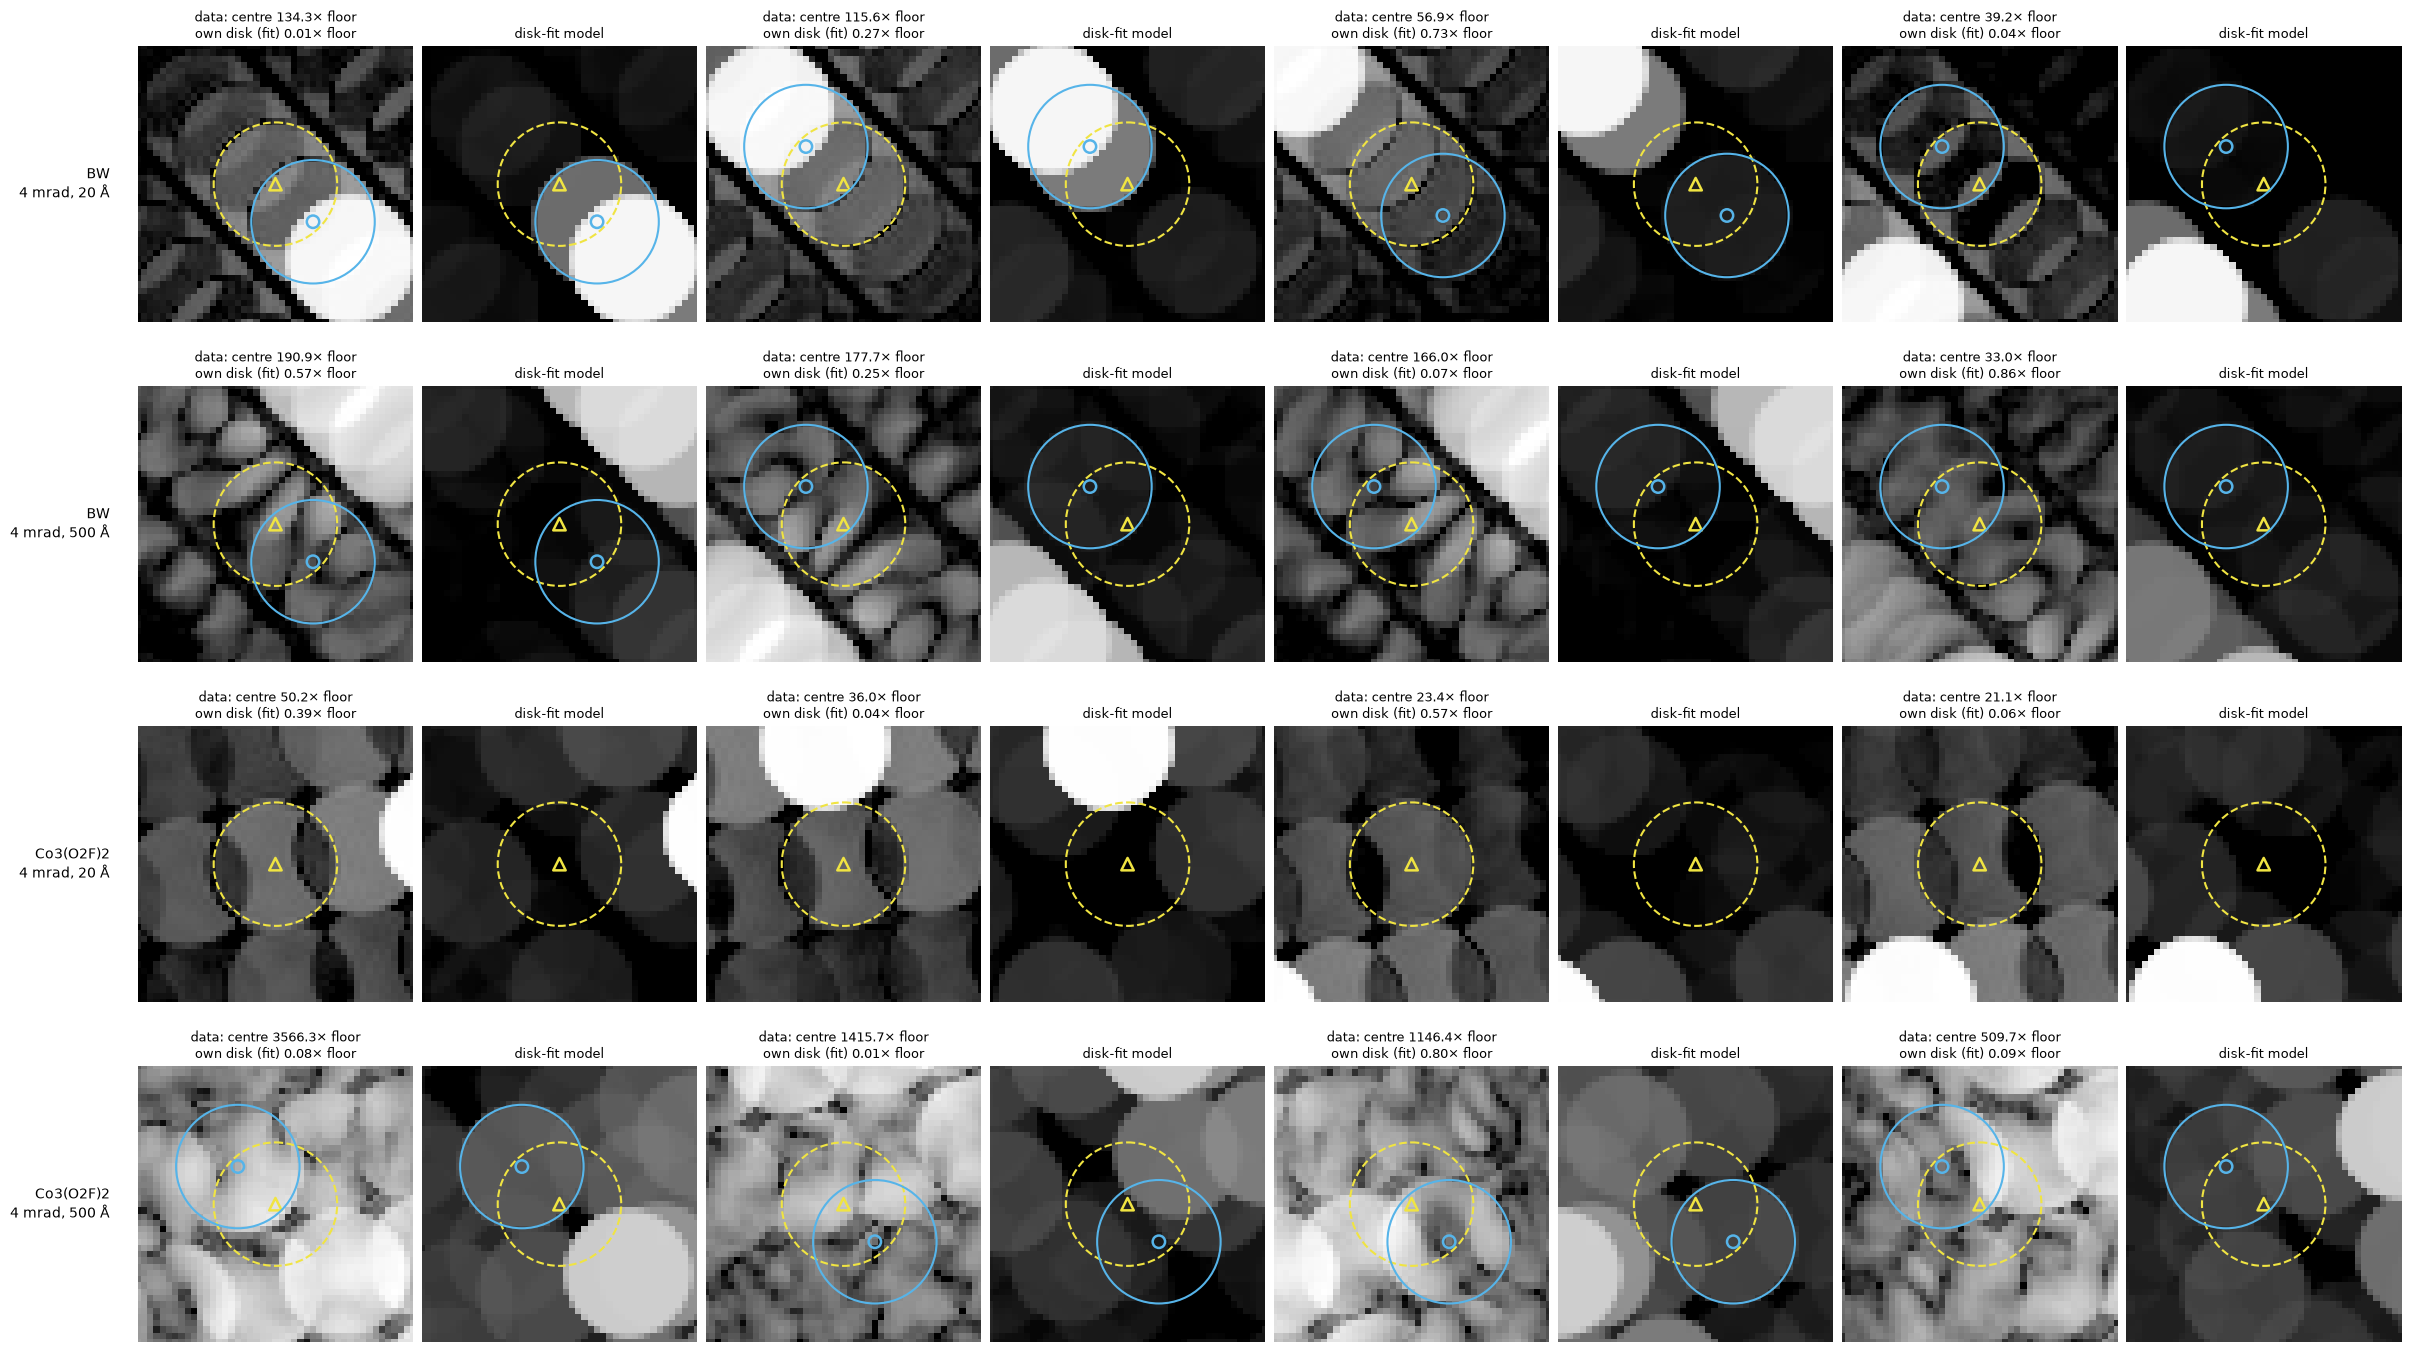

In [8]:
N_ZOOM, HALF = 4, 22  # zooms per pattern, half-width in px

keys4 = [k for k in AUDIT if k[1] == 4]
fig, axs = plt.subplots(len(keys4), 2 * N_ZOOM, figsize=(3 * 2 * N_ZOOM, 3.4 * len(keys4)),
                        constrained_layout=True, squeeze=False)
for row, key in zip(axs, keys4):
    img, gt, probe, df, g, r = TABLES[key]
    p = df[["y", "x"]].values
    lit = df[df.neighbour_lit].sort_values("own", ascending=False)
    norm_ = LogNorm(vmin=g["floor"], vmax=img.max())
    for n in range(N_ZOOM):
        ax_d, ax_m = row[2 * n], row[2 * n + 1]
        ax_d.axis("off"); ax_m.axis("off")
        if n >= len(lit):
            if n == 0:
                ax_d.text(0.5, 0.5, "no neighbour-lit\ncandidates", ha="center", va="center", transform=ax_d.transAxes)
            continue
        i = lit.index[n]
        s = df.loc[i]
        k = light_at(df, df.own_fit.values, i, r)
        for ax, im, label in [(ax_d, img, "data"), (ax_m, g["model"], "disk-fit model")]:
            ax.imshow(im, cmap=GRAY, norm=norm_)
            ax.add_patch(Circle((s.x, s.y), r, fill=False, ec=YELLOW, lw=1.5, ls="--"))
            ax.scatter([s.x], [s.y], marker="^", s=80, facecolors="none", edgecolors=YELLOW, linewidths=1.8)
            if k is not None:
                ax.add_patch(Circle((p[k][1], p[k][0]), r, fill=False, ec=SKY, lw=1.5))
                ax.scatter([p[k][1]], [p[k][0]], marker="o", s=80, facecolors="none", edgecolors=SKY, linewidths=1.8)
            ax.set_xlim(s.x - HALF, s.x + HALF); ax.set_ylim(s.y + HALF, s.y - HALF)
            ax.set_title(label, fontsize=9)
        ax_d.set_title(f"data: centre {s.own:.1f}× floor\nown disk (fit) {s.own_fit:.2f}× floor", fontsize=9)
    row[0].text(-0.1, 0.5, f"{key[0]}\n4 mrad, {key[2]} Å", transform=row[0].transAxes, ha="right", va="center")
plt.show()

## 1.5 Decision: is *visible* a reliable training target?

`doubtful_frac` in the table below is the fraction of visible labels that are box-only or neighbour-lit. Rough guide for the training target in section 3:

| what the audit shows | training target |
|---|---|
| 1 mrad centres aligned (abs(median offset) < 0.25 px) **and** `doubtful_frac` small (≲ 5 %) at every angle | `visible` (3 × 3 rule as in the reference) |
| `doubtful_frac` large at 4 mrad, `fit_error` small | `visible_fit`: visibility from the disk fit (`own_fit ≥ 1`) instead of the 3 × 3 box |
| `doubtful_frac` large and `fit_error` large (disk model does not hold) | `all` candidates, or `visible` for 1–2 mrad and `all` for 4 mrad |
| systematic centre offset at 1 mrad | fix the label convention (shift) first, then re-run this audit |
| visible counts change a lot between 1 × 1, 3 × 3 and 5 × 5 | the floor rule is fragile; prefer `visible_fit` or `all` |

The decision is recorded in `TARGETS` and used by the fine-tuning section.

### Outcome of the audit

- **Labels reproduce the reference** (1.1) and **are aligned** (1.3): median offset ≤ 0.1 px; the RMS of ≈ 0.38 px at 20 Å is what whole-pixel labels give by rounding alone (0.29 px per axis, ≈ 0.41 px in 2D).
- **The disk fit does not hold** (`fit_error` 0.30–0.89), so `neighbour_lit`, `visible_fit` and `doubtful_frac` are not usable, and the first condition of the `all` row above (`doubtful_frac` large) was **never established**. Two checks on the cause:
  - *Not the extra weak disks:* re-running 1.2 with `EXTRA_REL = 0.02` (no extra disks) leaves the 1 mrad `neighbour_lit` counts unchanged (BW 33 / 109, Co₃(O₂F)₂ 4 / 76).
  - *At 1 mrad it is a threshold mismatch, not neighbour light:* no labelled disk covers a 1 mrad centre (`covered` = 0), and the brightest 1 mrad "neighbour-lit" disk (BW, 20 Å) has its centre at only 1.4× the floor and `own_fit` = 1.000 (just under 1), with the model matching the data. The visibility test uses the **maximum** of the 3 × 3 box, the fit gives the disk's **mean** level, so disks at the floor pass one and fail the other.
  - *At 4 mrad the fit genuinely fails:* e.g. BW 4 mrad 20 Å, a candidate lit at 134× the floor inside its own (overlapped) disk gets `own_fit` 0.01. Flat probe-shaped disks cannot model the dynamical structure inside overlapping disks (dark lines in the zooms of 1.4).
- **1 and 2 mrad: `visible` is reliable.** The 3 × 3 box (±1 px) stays inside the candidate's own disk, no neighbour's disk covers the centre (`covered` = 0), and `box_only` there is the disk's own edge pixels.
- **4 mrad: not decided.** Every centre lies inside neighbouring disks, so the centre pixel can be lit by neighbours; the audit could not test whether that happens, because the disk fit fails. It did **not** show the `visible` labels are wrong.

**Decision.** `TARGETS` is `visible` at 1 and 2 mrad and **open at 4 mrad**, to be settled by experiment in section 3: fine-tune once with `visible` and once with `all` targets, and score both with the same visible-spot metrics. `all` is not a free default: it asks a local detector to place spots where the image has no intensity (it can only do that by inferring the lattice, which risks false detections), and it is not threshold-free either (the 2 % `dataPots` cut gives 136 candidates for Co₃(O₂F)₂ at 20 Å but 222 at 500 Å).

In [9]:
summary = audit[["eta", "candidates", "visible", "visible_1x1", "visible_5x5", "visible_fit", "box_only", "neighbour_lit",
                 "doubtful_frac", "fit_error"]]
print(summary.to_string())
print("\n1 mrad alignment:\n" + alignment[["disks", "median_dy", "median_dx", "rms"]].to_string())

TARGETS = {1: "visible", 2: "visible", 4: None}  # 4 mrad: decided in section 3 by a visible-vs-all fine-tuning comparison

                             eta  candidates  visible  visible_1x1  visible_5x5  visible_fit  box_only  neighbour_lit  doubtful_frac  fit_error
material  angle  thickness                                                                                                                     
BW        1 mrad 20 Å       0.61         280      170          153          177          137        17             33          0.194      0.365
                 500 Å      0.61         322      294          214          306          185        80            109          0.405      0.836
          2 mrad 20 Å       1.10         280      163          130          176           47        33            116          0.712      0.598
                 500 Å      1.10         322      290          203          314          143        87            147          0.572      0.726
          4 mrad 20 Å       2.32         282      111           88          132           10        23            101          0.910    

## 2. Zero-shot baseline on all materials

What the pretrained `general` model already achieves on every material, with the **shared pipelines** of `load_diffraction.ipynb` (section 4): settings chosen once and used for all materials. The BW-tuned settings and the other pretrained models of that notebook are not used here, because they were picked on BW.

| angle | pipeline | settings |
|---|---|---|
| 1 mrad | log image → Spotiflow | log ×1000, threshold 0.5 |
| 2 mrad | ring correlation → Spotiflow | log ×10000, edge σ 0.5, threshold 0.5 |
| 4 mrad | ring correlation → Spotiflow | log ×10000, edge σ 1, threshold 0.3 |

All 25 materials × 3 angles × 5 thicknesses (20, 40, 100, 200, 500 Å) = 375 patterns. Scoring as in the reference: predictions within 3 px of the central beam are ignored, one-to-one matching within `CUTOFF` = 3 px. Reported per pattern: **visible recall** (found visible / visible), **overall recall** (found / all candidates), **precision** (found / predicted), and the counts behind them, including `found_not_vis` (found candidates with no visible intensity) and `truly_false` (false detections near nothing: no missed candidate within 5 px, no weaker 1–2 % `dataPots` peak within 3 px), as in `load_diffraction.ipynb`. Overall recall is shown because the 4 mrad training target is still open (`visible` vs `all`); this baseline does not depend on that choice.

The BW rows at 20 and 40 Å must reproduce the shared-settings table of `load_diffraction.ipynb`; this is checked below. The table is saved to `diffraction_runs/zero_shot.csv` so that section 3 can compare against it.

In [10]:
import logging

from scipy.ndimage import gaussian_filter
from skimage.filters import sobel
from spotiflow.model import Spotiflow
from spotiflow.utils import normalize
from spotiflow.utils.matching import points_matching

logging.getLogger("spotiflow.model.spotiflow").setLevel(logging.WARNING)  # hide per-prediction INFO messages

CUTOFF = 3                              # px, as in the reference
NEAR_R = 5                              # px: a false detection this close to a missed candidate is 'near a real spot'
THICKNESSES = [20, 40, 100, 200, 500]   # Å
SHARED = {  # copied from load_diffraction.ipynb, section 4
    1: ("log",  dict(log_scale=1000, prob_thresh=0.5)),
    2: ("ring", dict(log_scale=10000, edge_sigma=0.5, prob_thresh=0.5)),
    4: ("ring", dict(log_scale=10000, edge_sigma=1, prob_thresh=0.3)),
}
MODEL = Spotiflow.from_pretrained("general")


def detect(img, probe, method, log_scale, prob_thresh, edge_sigma=None, model=MODEL):
    """Spotiflow input as in load_diffraction.ipynb (log image, or ring correlation of Sobel edges), then Spotiflow."""
    x = np.log1p(img / img.max() * log_scale)
    if method == "ring":
        r = disk_radius(probe)
        cy, cx = np.argwhere(img > img.max() / 2).mean(axis=0)  # central beam
        yy, xx = np.indices(img.shape)
        edges = sobel(gaussian_filter(x, edge_sigma)) * (np.hypot(yy - cy, xx - cx) > r + 3)
        ring = sobel(gaussian_filter(probe.astype(float), edge_sigma))
        F = np.fft.fft2(edges) * np.conj(np.fft.fft2(np.fft.ifftshift(ring)))
        x = np.clip(np.real(np.fft.ifft2(F)), 0, None)
    pred, _ = model.predict(x, min_distance=3, prob_thresh=prob_thresh, normalizer=lambda im: normalize(im, 1, 99.8),
                            subpix=True, verbose=False)
    return pred


def score(img, gt, pred):
    """Scored as score_spots in load_diffraction.ipynb. A false detection is 'truly false' if it is neither within
    NEAR_R of a missed candidate nor within CUTOFF of a weaker (1-2 %) dataPots peak."""
    g = ground_truth(img, gt)
    pts, vis = g["points"], g["visible"]
    pred = pred[off_beam(pred, g["beam"])] if len(pred) else pred.reshape(0, 2)
    found = np.zeros(len(pts), bool)
    fp = np.arange(len(pred))
    if len(pred):
        m = points_matching(pts, pred, cutoff_distance=CUTOFF)
        found[[a for a, _ in m.matched_pairs]] = True
        fp = np.array(m.false_positives, dtype=int)
    rest = fp  # false detections not near a missed candidate
    if len(fp) and (~found).any():
        rest = fp[list(points_matching(pts[~found], pred[fp], cutoff_distance=NEAR_R).false_positives)]
    peaks_1pct = peak_local_max(gt, min_distance=3, threshold_rel=0.01, exclude_border=False)
    weak = peaks_1pct[gt[tuple(peaks_1pct.T)] < gt[tuple(pts.T)].min()]
    truly_false = len(rest)
    if len(rest) and len(weak):
        truly_false = len(points_matching(weak, pred[rest], cutoff_distance=CUTOFF).false_positives)
    return dict(candidates=len(pts), visible=int(vis.sum()), predicted=len(pred),
                found_vis=int((found & vis).sum()), found_not_vis=int((found & ~vis).sum()), found_all=int(found.sum()),
                false=len(pred) - int(found.sum()), truly_false=truly_false,
                recall_vis=(found & vis).sum() / max(vis.sum(), 1), recall_all=found.mean(),
                precision=found.sum() / len(pred) if len(pred) else np.nan)


rows = []
for material in MATERIALS:
    for angle, (method, kw) in SHARED.items():
        for thickness in THICKNESSES:
            img, gt, probe = load_slice(material, angle, thickness)
            rows.append(dict(material=material, angle=angle, thickness=thickness, **score(img, gt, detect(img, probe, method, **kw))))
zero_shot = pd.DataFrame(rows)
Path("diffraction_runs").mkdir(exist_ok=True)
zero_shot.to_csv("diffraction_runs/zero_shot.csv", index=False)
print(f"{len(zero_shot)} patterns scored, saved to diffraction_runs/zero_shot.csv")

# BW at 20 / 40 Å must match load_diffraction.ipynb (shared settings): (found visible, visible, predicted, found not visible, truly false)
REF_BW = {(1, 20): (170, 170, 213, 43, 0), (1, 40): (269, 269, 278, 4, 0), (2, 20): (41, 163, 44, 0, 3),
          (2, 40): (100, 224, 103, 0, 3), (4, 20): (17, 111, 22, 0, 1), (4, 40): (13, 150, 22, 0, 1)}
COLS = ["found_vis", "visible", "predicted", "found_not_vis", "truly_false"]
bw = zero_shot[zero_shot.material == "BW"].set_index(["angle", "thickness"])
got = {k: tuple(int(bw.loc[k, c]) for c in COLS) for k in REF_BW}
for k in REF_BW:
    print(f"BW {k[0]} mrad {k[1]} Å: {' / '.join(COLS)} = {got[k]} (reference {REF_BW[k]})")
if CHECK_REFERENCE:
    assert got == REF_BW, "zero-shot baseline does NOT reproduce load_diffraction.ipynb"
    print("PASS: BW baseline reproduces load_diffraction.ipynb")

375 patterns scored, saved to diffraction_runs/zero_shot.csv
BW 1 mrad 20 Å: found_vis / visible / predicted / found_not_vis / truly_false = (170, 170, 213, 43, 0) (reference (170, 170, 213, 43, 0))
BW 1 mrad 40 Å: found_vis / visible / predicted / found_not_vis / truly_false = (269, 269, 278, 4, 0) (reference (269, 269, 278, 4, 0))
BW 2 mrad 20 Å: found_vis / visible / predicted / found_not_vis / truly_false = (41, 163, 44, 0, 3) (reference (41, 163, 44, 0, 3))
BW 2 mrad 40 Å: found_vis / visible / predicted / found_not_vis / truly_false = (100, 224, 103, 0, 3) (reference (100, 224, 103, 0, 3))
BW 4 mrad 20 Å: found_vis / visible / predicted / found_not_vis / truly_false = (17, 111, 22, 0, 1) (reference (17, 111, 22, 0, 1))
BW 4 mrad 40 Å: found_vis / visible / predicted / found_not_vis / truly_false = (13, 150, 22, 0, 1) (reference (13, 150, 22, 0, 1))
PASS: BW baseline reproduces load_diffraction.ipynb


Zero-shot baseline, shared settings, 25 materials: median [25 %, 75 %] across materials

                        recall_vis         recall_all          precision
angle thickness                                                         
1     20         1.00 [0.88, 1.00]  0.52 [0.42, 0.61]  0.97 [0.89, 0.99]
      40         0.91 [0.75, 0.99]  0.57 [0.38, 0.62]  0.90 [0.80, 0.98]
      100        0.66 [0.40, 0.85]  0.44 [0.23, 0.58]  0.86 [0.75, 0.97]
      200        0.48 [0.18, 0.56]  0.36 [0.18, 0.50]  0.83 [0.73, 0.90]
      500        0.25 [0.03, 0.39]  0.25 [0.03, 0.34]  0.78 [0.64, 0.95]
2     20         0.57 [0.30, 0.92]  0.24 [0.15, 0.42]  0.94 [0.88, 1.00]
      40         0.49 [0.20, 0.71]  0.31 [0.17, 0.44]  0.91 [0.86, 0.93]
      100        0.26 [0.09, 0.48]  0.22 [0.08, 0.33]  0.86 [0.75, 0.95]
      200        0.15 [0.06, 0.24]  0.12 [0.06, 0.23]  0.94 [0.82, 0.96]
      500        0.04 [0.02, 0.07]  0.04 [0.02, 0.07]  0.92 [0.80, 1.00]
4     20         0.29 [0.19, 0.51] 

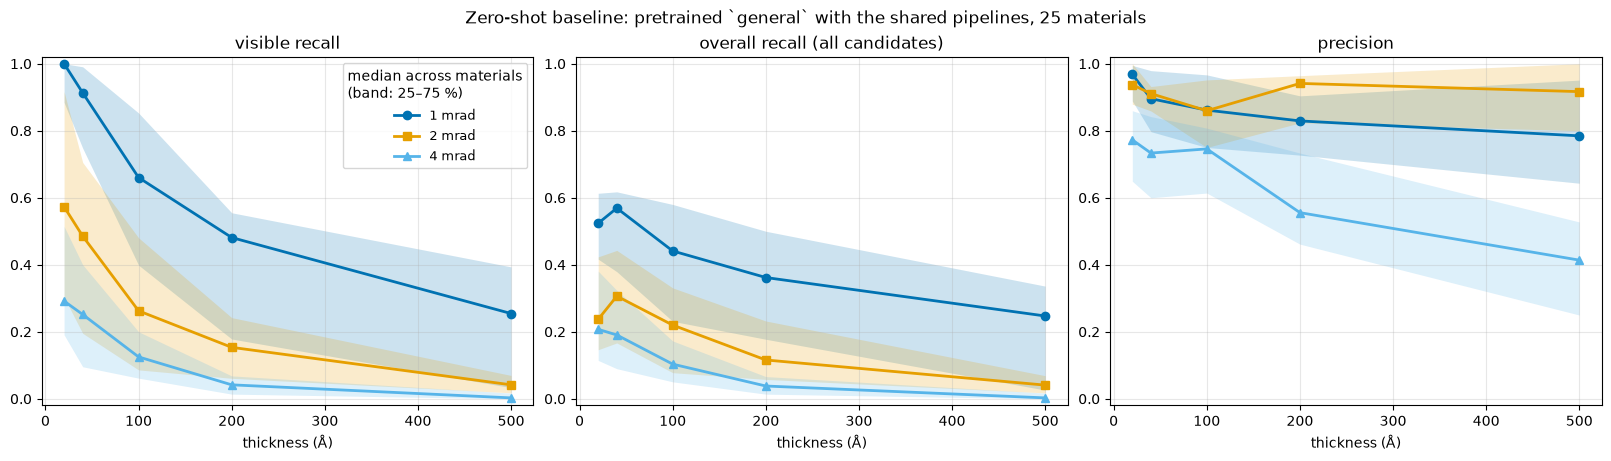


Visible recall per material at 20 Å (sorted by 2 mrad):

               1 mrad  2 mrad  4 mrad
material                             
Ba2Mn3O8         1.00    1.00    0.75
SiO2             1.00    1.00    0.64
Co3(O2F)2        1.00    0.98    0.41
AlPO4            1.00    0.96    0.34
FeB              1.00    0.94    0.59
ZrSn3            1.00    0.92    0.79
LiMnCrO4         1.00    0.92    0.79
SbPbO3           1.00    0.83    0.54
Mn6O5F7          1.00    0.77    0.28
Al(NiO2)3        1.00    0.72    0.19
AlCo3            1.00    0.71    0.43
Li7Mn2(CoO4)3    1.00    0.66    0.50
CoSbS            1.00    0.57    0.51
AlPt2            0.88    0.43    0.29
Na2O             1.00    0.42    0.20
RbCaMg6          1.00    0.37    0.21
HoTe3            0.87    0.34    0.32
SiI3             0.98    0.31    0.05
NbTe4Ir          0.86    0.30    0.19
BW               1.00    0.25    0.15
Pr4Sb3           0.93    0.24    0.13
Mg2B4H22C2S      0.73    0.22    0.25
U3Bi4Rh3         0.86    0.18 

In [11]:
METRICS = ["recall_vis", "recall_all", "precision"]
q = lambda p: (lambda s: s.quantile(p))
summary2 = zero_shot.groupby(["angle", "thickness"])[METRICS].agg(["median", q(0.25), q(0.75)])
summary2.columns = [f"{m}_{s}" for m, s in zip(summary2.columns.get_level_values(0), ["median", "q25", "q75"] * len(METRICS))]
print("Zero-shot baseline, shared settings, 25 materials: median [25 %, 75 %] across materials\n")
table = pd.DataFrame({m: [f"{a:.2f} [{b:.2f}, {c:.2f}]" for a, b, c in summary2[[f"{m}_median", f"{m}_q25", f"{m}_q75"]].values]
                      for m in METRICS}, index=summary2.index)
print(table.to_string())

COUNTS = ["candidates", "visible", "found_vis", "found_not_vis", "predicted", "truly_false"]
print("\nCounts per pattern, median across materials. Recall can fall because the visible set grows (denominator)\n"
      "or because fewer spots are found (numerator); found_vis shows which:\n")
print(zero_shot.groupby(["angle", "thickness"])[COUNTS].median().astype(int).to_string())

# one line per angle, median across materials with the 25-75 % band; colour-blind safe colours + distinct markers
STYLE = {1: (BLUE, "o"), 2: (ORANGE, "s"), 4: (SKY, "^")}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, m, title in zip(axs, METRICS, ["visible recall", "overall recall (all candidates)", "precision"]):
    for angle, (col, mk) in STYLE.items():
        s = summary2.loc[angle]
        ax.fill_between(s.index, s[f"{m}_q25"], s[f"{m}_q75"], color=col, alpha=0.2, lw=0)
        ax.plot(s.index, s[f"{m}_median"], color=col, marker=mk, lw=2, label=f"{angle} mrad")
    ax.set_xlabel("thickness (Å)"); ax.set_ylim(-0.02, 1.02); ax.set_title(title); ax.grid(alpha=0.3)
axs[0].legend(title="median across materials\n(band: 25–75 %)", fontsize=9)
fig.suptitle("Zero-shot baseline: pretrained `general` with the shared pipelines, 25 materials")
plt.show()

print("\nVisible recall per material at 20 Å (sorted by 2 mrad):\n")
per_mat = zero_shot[zero_shot.thickness == 20].pivot(index="material", columns="angle", values="recall_vis")
per_mat.columns = [f"{a} mrad" for a in per_mat.columns]
print(per_mat.sort_values("2 mrad", ascending=False).round(2).to_string())

**Result (zero-shot baseline).**

- **Recall falls with thickness, for two different reasons** (counts table, median across materials, 20 → 500 Å):
  - *1 mrad: mostly a bigger denominator.* The visible set grows from 68 to 266 spots per pattern, while the number found falls only from 68 to 44. Most of the drop in visible recall (1.00 → 0.25) comes from many more spots becoming visible, not from worse detection.
  - *2 and 4 mrad: real loss of detection.* The visible set grows (82 → 287, 138 → 279), but the number found also collapses (44 → 10, 36 → 1).
- **Part of the drop is untuned settings.** The shared settings were chosen on BW at 20 / 40 Å. At 500 Å the dynamic range and the structure inside disks are different, and the number of predictions falls with thickness at every angle (e.g. 1 mrad: 112 → 67), which points at the fixed threshold and log scale. This baseline is a fair reference, but some of what fine-tuning gains at large thickness could also be gained by tuning settings per thickness; section 3 should keep that in mind.
- **Materials differ a lot.** At 2 mrad, 20 Å, visible recall ranges from 1.00 (Ba₂Mn₃O₈, SiO₂) to 0.02 (Nd₄Rh₆Pb₁₉); the 25–75 % band is 0.30–0.92. **BW is one of the harder materials** (2 mrad: 0.25, against a median of 0.57), so BW results from `load_diffraction.ipynb` are not representative of the typical case.
- **Precision stays high at 1 and 2 mrad** (median 0.78–0.97). At 4 mrad it drops with thickness (0.77 → 0.41), but read it with the counts: at 500 Å a pattern has only about **4 predictions, 2 of them false**. The low precision there is mostly a small-number effect of Spotiflow predicting almost nothing, not the ring correlation firing widely. Where it does fire falsely, structure inside overlapping disks (which the disk fit of 1.4 could not model) is a plausible cause, not tested here.
- **Overall recall is about half of visible recall at 1 mrad, 20 Å**: about half of the candidates carry no intensity above the floor. That gap is what an `all` target would ask the model to fill.

These per-pattern numbers (`diffraction_runs/zero_shot.csv`) are the reference for section 3. Once the material split is fixed there, the baseline should be quoted on the **test materials only**, at the same 5 thicknesses.